# Week 02: The Maths Behind Machine Learning — Support Notebook

Linear algebra, calculus and optimization, probability and statistics, NumPy and Pandas.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
print(np.__version__)
print(pd.__version__)

1.26.4
2.3.3


## 1. Linear Algebra

### 1.1 Scalar, Vector, Matrix, Tensor

| Object | Dims | Example |
|---|---|---|
| Scalar | 0-D | temperature |
| Vector | 1-D | one house: beds, sq ft, baths |
| Matrix | 2-D | table of houses, grayscale image |
| Tensor | 3-D+ | colour image: height × width × 3 |

In [2]:
scalar = np.array(31)
vector = np.array([3, 1200, 2])
matrix = np.array([[3, 1200, 2],
                   [2,  850, 1],
                   [4, 1800, 3]])
tensor = np.random.randint(0, 256, size=(4, 4, 3))

for name, a in [("scalar", scalar), ("vector", vector), ("matrix", matrix), ("tensor", tensor)]:
    print(f"{name:7s} ndim={a.ndim} shape={a.shape}")

scalar  ndim=0 shape=()
vector  ndim=1 shape=(3,)
matrix  ndim=2 shape=(3, 3)
tensor  ndim=3 shape=(4, 4, 3)


### 1.2 Images as Numbers

A grayscale image is a matrix of brightness values in $[0, 255]$. A colour image is a tensor of shape $(H, W, 3)$.

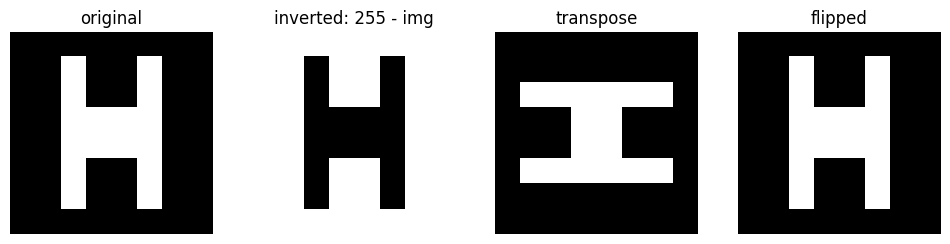

[[  0   0   0   0   0   0   0   0]
 [  0   0 255   0   0 255   0   0]
 [  0   0 255   0   0 255   0   0]
 [  0   0 255 255 255 255   0   0]
 [  0   0 255 255 255 255   0   0]
 [  0   0 255   0   0 255   0   0]
 [  0   0 255   0   0 255   0   0]
 [  0   0   0   0   0   0   0   0]]


In [3]:
img = np.zeros((8, 8), dtype=np.uint8)
img[1:7, 2] = 255
img[1:7, 5] = 255
img[3:5, 2:6] = 255

fig, ax = plt.subplots(1, 4, figsize=(12, 3))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("original")
ax[1].imshow(255 - img, cmap="gray"); ax[1].set_title("inverted: 255 - img")
ax[2].imshow(img.T, cmap="gray"); ax[2].set_title("transpose")
ax[3].imshow(np.fliplr(img), cmap="gray"); ax[3].set_title("flipped")
for a in ax: a.axis("off")
plt.show()
print(img)

### 1.3 Vector Operations

$$\mathbf{a} + \mathbf{b} = [a_1 + b_1, \dots, a_n + b_n] \qquad c\,\mathbf{a} = [c a_1, \dots, c a_n]$$

a + b = [6 4]
a - b = [-2  2]
3a    = [6 9]


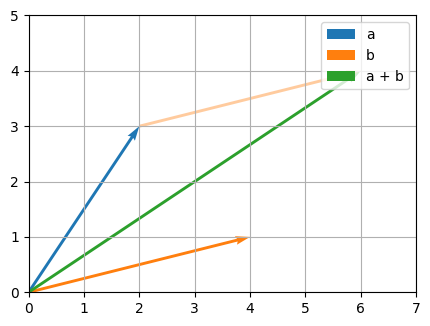

In [4]:
a = np.array([2, 3])
b = np.array([4, 1])

print("a + b =", a + b)
print("a - b =", a - b)
print("3a    =", 3 * a)

plt.figure(figsize=(5, 5))
plt.quiver(0, 0, *a, angles="xy", scale_units="xy", scale=1, color="tab:blue", label="a")
plt.quiver(0, 0, *b, angles="xy", scale_units="xy", scale=1, color="tab:orange", label="b")
plt.quiver(0, 0, *(a + b), angles="xy", scale_units="xy", scale=1, color="tab:green", label="a + b")
plt.quiver(*a, *b, angles="xy", scale_units="xy", scale=1, color="tab:orange", alpha=0.4)
plt.xlim(0, 7); plt.ylim(0, 5); plt.grid(True); plt.legend(); plt.gca().set_aspect("equal")
plt.show()

### 1.4 Dot Product

$$\mathbf{a} \cdot \mathbf{b} = \sum_{i=1}^{n} a_i b_i \qquad [2, 3] \cdot [4, 1] = 2 \times 4 + 3 \times 1 = 11$$

Two vectors in, one number out.

In [5]:
def dot(a, b):
    total = 0
    for ai, bi in zip(a, b):
        total += ai * bi
    return total

print(dot(a, b))
print(np.dot(a, b))
print(a @ b)

11
11
11


### 1.5 Vector Norms and Distances

$$\|\mathbf{x}\|_1 = \sum_i |x_i| \qquad \|\mathbf{x}\|_2 = \sqrt{\sum_i x_i^2} = \sqrt{\mathbf{x} \cdot \mathbf{x}}$$

$$d_{\text{Manhattan}}(\mathbf{a}, \mathbf{b}) = \|\mathbf{a} - \mathbf{b}\|_1 \qquad d_{\text{Euclidean}}(\mathbf{a}, \mathbf{b}) = \|\mathbf{a} - \mathbf{b}\|_2$$

In [ ]:
def l1_norm(x):
    return np.sum(np.abs(x))

def l2_norm(x):
    return np.sqrt(np.sum(x ** 2))

def manhattan(a, b):
    return l1_norm(a - b)

def euclidean(a, b):
    return l2_norm(a - b)

x = np.array([3, -4])
print("L1:", l1_norm(x), np.linalg.norm(x, 1))
print("L2:", l2_norm(x), np.linalg.norm(x))

p, q = np.array([1, 2]), np.array([4, 6])
print("Manhattan:", manhattan(p, q))
print("Euclidean:", euclidean(p, q))

### 1.6 Angle and Cosine Similarity

$$\cos\theta = \frac{\mathbf{a} \cdot \mathbf{b}}{\|\mathbf{a}\|_2 \, \|\mathbf{b}\|_2}$$

$1$ = same direction, $0$ = perpendicular, $-1$ = opposite. Used to compare text embeddings and recommendations.

In [ ]:
def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

print(cosine_similarity(np.array([1, 0]), np.array([2, 0])))
print(cosine_similarity(np.array([1, 0]), np.array([0, 5])))
print(cosine_similarity(np.array([1, 0]), np.array([-3, 0])))

cos = cosine_similarity(a, b)
print(f"a, b: cos = {cos:.3f}, angle = {np.degrees(np.arccos(cos)):.1f} deg")

In [ ]:
movies = ["action", "comedy", "romance", "sci-fi"]
user_a = np.array([5, 1, 0, 4])
user_b = np.array([4, 0, 1, 5])
user_c = np.array([0, 5, 5, 1])

print("A vs B:", round(cosine_similarity(user_a, user_b), 3))
print("A vs C:", round(cosine_similarity(user_a, user_c), 3))

### 1.7 Matrix Multiplication

$$(m \times n) \cdot (n \times p) \rightarrow (m \times p) \qquad C_{ij} = \sum_{k=1}^{n} A_{ik} B_{kj} = \text{row}_i(A) \cdot \text{col}_j(B)$$

Inner sizes must match. Every entry is one dot product, which is why GPUs can compute them in parallel.

In [ ]:
def matmul(A, B):
    m, n = A.shape
    n2, p = B.shape
    assert n == n2, f"inner sizes must match: {A.shape} @ {B.shape}"
    C = np.zeros((m, p))
    for i in range(m):
        for j in range(p):
            C[i, j] = np.dot(A[i, :], B[:, j])
    return C

A = np.array([[2, 3],
              [1, 5]])
w = np.array([[4],
              [1]])

print(matmul(A, w))
print(A @ w)
print("shapes:", A.shape, "@", w.shape, "->", (A @ w).shape)

In [ ]:
M = np.random.rand(3, 4)
N = np.random.rand(4, 2)
print((M @ N).shape)

try:
    M @ M
except ValueError as e:
    print("ValueError:", e)

In [ ]:
P = np.array([[1, 2], [3, 4]])
Q = np.array([[0, 1], [1, 0]])
print("PQ =\n", P @ Q)
print("QP =\n", Q @ P)
print("element-wise P * Q =\n", P * Q)

Matrix multiplication is **not commutative**: $AB \neq BA$ in general. `*` is element-wise, `@` is matrix multiplication.

### 1.8 Transpose

$$(A^T)_{ij} = A_{ji} \qquad (AB)^T = B^T A^T$$

In [ ]:
print(A.T)
print(np.allclose((A @ P).T, P.T @ A.T))

### 1.9 Identity, Inverse, Singularity

$$I\mathbf{x} = \mathbf{x} \qquad A A^{-1} = A^{-1} A = I$$

For a $2 \times 2$ matrix:

$$A = \begin{bmatrix} a & b \\ c & d \end{bmatrix} \quad \det(A) = ad - bc \quad A^{-1} = \frac{1}{ad - bc}\begin{bmatrix} d & -b \\ -c & a \end{bmatrix}$$

If $\det(A) = 0$ the matrix is **singular** and has no inverse (its columns are linearly dependent).

In [ ]:
I = np.eye(2)
print(I @ A)

A_inv = np.linalg.inv(A)
print("det(A) =", np.linalg.det(A))
print("A^-1 =\n", A_inv)
print("A @ A^-1 =\n", A @ A_inv)

S = np.array([[1, 2],
              [2, 4]])
print("det(S) =", np.linalg.det(S))
try:
    np.linalg.inv(S)
except np.linalg.LinAlgError as e:
    print("LinAlgError:", e)

### 1.10 Linear Transformations

A matrix maps vectors to new vectors. Rotation by $\theta$:

$$R(\theta) = \begin{bmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{bmatrix}$$

In [ ]:
square = np.array([[0, 1, 1, 0, 0],
                   [0, 0, 1, 1, 0]])

theta = np.radians(45)
R = np.array([[np.cos(theta), -np.sin(theta)],
              [np.sin(theta),  np.cos(theta)]])
scale = np.array([[2, 0], [0, 0.5]])
shear = np.array([[1, 1], [0, 1]])

plt.figure(figsize=(6, 6))
plt.plot(*square, label="original")
plt.plot(*(R @ square), label="rotate 45")
plt.plot(*(scale @ square), label="scale")
plt.plot(*(shear @ square), label="shear")
plt.grid(True); plt.legend(); plt.gca().set_aspect("equal")
plt.show()

### 1.11 Projection

Projection of $\mathbf{a}$ onto $\mathbf{b}$:

$$\text{proj}_{\mathbf{b}}\mathbf{a} = \frac{\mathbf{a} \cdot \mathbf{b}}{\mathbf{b} \cdot \mathbf{b}}\,\mathbf{b}$$

In [ ]:
proj = (a @ b) / (b @ b) * b
print("proj_b(a) =", proj)
print("residual . b =", round((a - proj) @ b, 10))

### 1.12 Features × Weights = Prediction

$$\hat{y} = w_1 x_1 + w_2 x_2 + b = \mathbf{w} \cdot \mathbf{x} + b$$

For a whole dataset $X$ of shape $(n, d)$:

$$\hat{\mathbf{y}} = X\mathbf{w} + b$$

Training = finding good $\mathbf{w}$ and $b$.

In [ ]:
x = np.array([1200, 3])
w = np.array([150, 10000])
b = 20000
print("one house:", w @ x + b)

X = np.array([[1200, 3],
              [ 850, 2],
              [1800, 4],
              [2400, 5]])
y_hat = X @ w + b
print("all houses:", y_hat)

In [ ]:
import time

n = 1_000_000
u = np.random.rand(n)
v = np.random.rand(n)

t = time.perf_counter(); s1 = dot(u, v); t_loop = time.perf_counter() - t
t = time.perf_counter(); s2 = u @ v;     t_vec = time.perf_counter() - t

print(f"loop:       {t_loop:.4f}s")
print(f"vectorized: {t_vec:.6f}s  ({t_loop / t_vec:.0f}x faster)")
print(np.isclose(s1, s2))

## 2. Calculus and Optimization

Learning loop: predict → measure error (loss) → find direction (gradient) → nudge weights → repeat.

### 2.1 Derivatives

$$f'(x) = \lim_{h \to 0} \frac{f(x + h) - f(x)}{h}$$

For $f(x) = x^2$: $f'(x) = 2x$, so $f'(3) = 6$. Sign: $+$ increasing, $-$ decreasing, $0$ flat.

In [ ]:
def f(x):
    return x ** 2

def numerical_derivative(f, x, h=1e-5):
    return (f(x + h) - f(x - h)) / (2 * h)

print("numerical f'(3):", numerical_derivative(f, 3))
print("analytic  f'(3):", 2 * 3)

In [ ]:
xs = np.linspace(-4, 4, 200)
x0 = 3
slope = 2 * x0
tangent = f(x0) + slope * (xs - x0)

plt.plot(xs, f(xs), label="f(x) = x^2")
plt.plot(xs, tangent, "--", label=f"tangent at x={x0}, slope={slope}")
plt.scatter([x0], [f(x0)], color="red", zorder=3)
plt.ylim(-2, 17); plt.grid(True); plt.legend()
plt.show()

### 2.2 Partial Derivatives and the Gradient

For a function of many variables, differentiate one at a time, holding others fixed:

$$f(w_1, w_2) = w_1^2 + 3w_2^2 \qquad \nabla f = \begin{bmatrix} \partial f / \partial w_1 \\ \partial f / \partial w_2 \end{bmatrix} = \begin{bmatrix} 2w_1 \\ 6w_2 \end{bmatrix}$$

The gradient points uphill. Gradient descent moves the opposite way.

In [ ]:
def f2(w):
    return w[0] ** 2 + 3 * w[1] ** 2

def grad_f2(w):
    return np.array([2 * w[0], 6 * w[1]])

def numerical_gradient(f, w, h=1e-5):
    g = np.zeros_like(w, dtype=float)
    for i in range(len(w)):
        e = np.zeros_like(w, dtype=float)
        e[i] = h
        g[i] = (f(w + e) - f(w - e)) / (2 * h)
    return g

w0 = np.array([1.0, 2.0])
print("analytic: ", grad_f2(w0))
print("numerical:", numerical_gradient(f2, w0))

### 2.3 Loss / Cost Function: MSE

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

Squaring removes negatives and punishes big misses more. Lower = better.

In [ ]:
def mse(y, y_hat):
    return np.mean((y - y_hat) ** 2)

y_true = np.array([3.0, 5.0, 7.0, 9.0])
y_good = np.array([3.1, 4.9, 7.2, 8.8])
y_bad  = np.array([1.0, 6.0, 4.0, 12.0])

print("good:", mse(y_true, y_good))
print("bad: ", mse(y_true, y_bad))

### 2.4 Gradient Descent (1 variable)

$$w_{\text{new}} = w_{\text{old}} - \alpha \cdot \frac{dL}{dw}$$

$\alpha$ = learning rate (step size). Stop when steps become tiny (converged).

In [ ]:
def L(w):
    return (w - 4) ** 2 + 1

def dL(w):
    return 2 * (w - 4)

def gradient_descent_1d(w, lr, steps):
    history = [w]
    for _ in range(steps):
        w = w - lr * dL(w)
        history.append(w)
    return np.array(history)

hist = gradient_descent_1d(w=-3.0, lr=0.1, steps=30)
print("final w:", hist[-1], " loss:", L(hist[-1]))

ws = np.linspace(-4, 12, 200)
plt.plot(ws, L(ws), label="L(w) = (w-4)^2 + 1")
plt.plot(hist, L(hist), "o-", color="red", ms=4, label="GD steps")
plt.xlabel("w"); plt.ylabel("loss"); plt.grid(True); plt.legend()
plt.show()

### 2.5 Learning Rate $\alpha$

Too small: slow. Too big: overshoots or diverges. Typical first tries: $0.1, 0.01, 0.001$.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, lr, title in zip(axes, [0.01, 0.3, 1.05], ["too small", "just right", "too big"]):
    h = gradient_descent_1d(w=-3.0, lr=lr, steps=20)
    ax.plot(ws, L(ws))
    ax.plot(h, L(h), "o-", color="red", ms=4)
    ax.set_title(f"lr = {lr} ({title}), final w = {h[-1]:.2f}")
    ax.set_ylim(0, 80); ax.set_xlim(-4, 12); ax.grid(True)
plt.show()

### 2.6 Gradient Descent in 2D

In [ ]:
def gradient_descent(grad, w, lr, steps):
    path = [w.copy()]
    for _ in range(steps):
        w = w - lr * grad(w)
        path.append(w.copy())
    return np.array(path)

path = gradient_descent(grad_f2, np.array([3.5, 2.0]), lr=0.1, steps=30)

g1, g2 = np.meshgrid(np.linspace(-4, 4, 200), np.linspace(-3, 3, 200))
Z = g1 ** 2 + 3 * g2 ** 2
plt.figure(figsize=(7, 5))
plt.contour(g1, g2, Z, levels=20, cmap="viridis")
plt.plot(path[:, 0], path[:, 1], "o-", color="red", ms=3)
plt.title(f"end: {path[-1].round(4)}"); plt.gca().set_aspect("equal")
plt.show()

### 2.7 Putting It Together: Fit $\hat{y} = wx + b$ with Gradient Descent

$$L(w, b) = \frac{1}{n}\sum_{i=1}^{n}\big(y_i - (w x_i + b)\big)^2$$

$$\frac{\partial L}{\partial w} = -\frac{2}{n}\sum_{i=1}^{n} x_i\,(y_i - \hat{y}_i) \qquad \frac{\partial L}{\partial b} = -\frac{2}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)$$

$$w \leftarrow w - \alpha\,\frac{\partial L}{\partial w} \qquad b \leftarrow b - \alpha\,\frac{\partial L}{\partial b}$$

In [ ]:
rng = np.random.default_rng(42)
x = rng.uniform(0, 10, 50)
y = 3 * x + 7 + rng.normal(0, 2, 50)

w, b = 0.0, 0.0
lr = 0.01
losses = []

for epoch in range(2000):
    y_hat = w * x + b
    error = y - y_hat
    dw = -2 * np.mean(x * error)
    db = -2 * np.mean(error)
    w -= lr * dw
    b -= lr * db
    losses.append(mse(y, y_hat))

print(f"learned: w = {w:.3f}, b = {b:.3f}   (true: w = 3, b = 7)")
print(f"final MSE: {losses[-1]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(x, y, s=15)
xx = np.linspace(0, 10, 100)
ax[0].plot(xx, w * xx + b, color="red")
ax[0].set_title("fitted line")
ax[1].plot(losses)
ax[1].set_yscale("log"); ax[1].set_title("MSE vs epoch"); ax[1].set_xlabel("epoch")
plt.show()

Same thing in matrix form: add a column of ones to $X$ so $b$ becomes a weight.

$$\hat{\mathbf{y}} = X\mathbf{w} \qquad \nabla_{\mathbf{w}} L = -\frac{2}{n} X^T(\mathbf{y} - X\mathbf{w})$$

Closed-form check (normal equation):

$$\mathbf{w}^* = (X^T X)^{-1} X^T \mathbf{y}$$

In [ ]:
Xb = np.column_stack([np.ones_like(x), x])
wv = np.zeros(2)
for _ in range(2000):
    grad = -2 / len(y) * Xb.T @ (y - Xb @ wv)
    wv -= 0.01 * grad

w_closed = np.linalg.inv(Xb.T @ Xb) @ Xb.T @ y
print("gradient descent [b, w]:", wv)
print("normal equation  [b, w]:", w_closed)

## 3. Probability and Statistics

### 3.1 Mean, Median, Variance, Standard Deviation

$$\mu = \frac{1}{n}\sum x_i \qquad \sigma^2 = \frac{1}{n}\sum (x_i - \mu)^2 \qquad s^2 = \frac{1}{n-1}\sum (x_i - \bar{x})^2 \qquad \sigma = \sqrt{\sigma^2}$$

Median = middle value of sorted data; robust to outliers.

In [ ]:
coffee = np.array([2, 4, 4, 4, 5, 5, 7, 9])

mean = coffee.sum() / len(coffee)
median = np.median(coffee)
var_pop = np.sum((coffee - mean) ** 2) / len(coffee)
var_sample = np.sum((coffee - mean) ** 2) / (len(coffee) - 1)

print("mean:           ", mean, np.mean(coffee))
print("median:         ", median)
print("variance (pop): ", var_pop, np.var(coffee))
print("std (pop):      ", np.sqrt(var_pop), np.std(coffee))
print("variance (samp):", round(var_sample, 3), round(np.var(coffee, ddof=1), 3))
print("std (samp):     ", round(np.sqrt(var_sample), 3))

In [ ]:
with_outlier = np.append(coffee, 100)
print("mean:  ", coffee.mean(), "->", round(with_outlier.mean(), 2))
print("median:", np.median(coffee), "->", np.median(with_outlier))

### 3.2 Normal Distribution

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}}\, e^{-\frac{(x - \mu)^2}{2\sigma^2}}$$

68-95-99.7 rule: about 68% within $1\sigma$, 95% within $2\sigma$, 99.7% within $3\sigma$.

In [ ]:
def normal_pdf(x, mu, sigma):
    return np.exp(-((x - mu) ** 2) / (2 * sigma ** 2)) / (sigma * np.sqrt(2 * np.pi))

heights = rng.normal(loc=170, scale=8, size=10_000)
mu, sigma = heights.mean(), heights.std()

xs = np.linspace(130, 210, 300)
plt.hist(heights, bins=60, density=True, alpha=0.5, label="samples")
plt.plot(xs, normal_pdf(xs, mu, sigma), color="red", label="normal pdf")
for k in [1, 2, 3]:
    plt.axvline(mu - k * sigma, color="gray", ls=":")
    plt.axvline(mu + k * sigma, color="gray", ls=":")
plt.xlabel("height (cm)"); plt.legend()
plt.show()

for k in [1, 2, 3]:
    frac = np.mean(np.abs(heights - mu) < k * sigma)
    print(f"within {k} sigma: {frac:.3f}")

### 3.3 Standardisation (z-score)

$$z = \frac{x - \mu}{\sigma}$$

Puts features on the same scale (mean 0, std 1). Values with $|z| > 3$ are possible outliers.

In [ ]:
houses = pd.DataFrame({
    "size_sqft": [850, 1200, 1500, 1800, 2400, 9000],
    "bedrooms":  [2, 3, 3, 4, 5, 4],
})

z = (houses - houses.mean()) / houses.std(ddof=0)
print(z.round(2))
print("mean:", z.mean().round(3).tolist(), " std:", z.std(ddof=0).round(3).tolist())

sizes = np.append(rng.normal(1500, 300, 200), 4000)
z_sizes = (sizes - sizes.mean()) / sizes.std()
print("outliers:", sizes[np.abs(z_sizes) > 3].round(0))

### 3.4 Probability Basics

$$0 \le P(A) \le 1 \qquad \sum_k P(\text{class}_k) = 1 \qquad P(A) \approx \frac{\text{count}(A)}{\text{total}}$$

A threshold (e.g. 0.5) turns a probability into a decision.

In [ ]:
flips = rng.integers(0, 2, size=10_000)
running = np.cumsum(flips) / np.arange(1, len(flips) + 1)

plt.plot(running)
plt.axhline(0.5, color="red", ls="--")
plt.xscale("log"); plt.xlabel("number of flips"); plt.ylabel("P(heads) estimate")
plt.show()
print("estimate after 10,000 flips:", running[-1])

Classifiers output scores (logits); **softmax** turns them into probabilities that sum to 1:

$$\text{softmax}(z_k) = \frac{e^{z_k}}{\sum_j e^{z_j}}$$

Binary case uses the **sigmoid**: $\sigma(z) = \dfrac{1}{1 + e^{-z}}$

In [ ]:
def softmax(z):
    e = np.exp(z - np.max(z))
    return e / e.sum()

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

classes = ["cat", "dog", "other"]
logits = np.array([2.5, 0.6, -0.8])
probs = softmax(logits)
for c, p in zip(classes, probs):
    print(f"{c:6s} {p:.2f}")
print("sum:", probs.sum())

spam_scores = np.array([-2.0, 0.1, 2.4, 0.8])
p_spam = sigmoid(spam_scores)
print("P(spam):  ", p_spam.round(2))
print("is spam:  ", p_spam >= 0.5)

## 4. NumPy in Action

In [ ]:
x = np.array([2, 3])
w = np.array([4, 1])
A = np.array([[2, 3],
              [1, 5]])

print(x.shape, A.shape)
print(np.dot(x, w))
print(A @ w)

In [ ]:
arr = np.arange(12).reshape(3, 4)
print(arr)
print("row 0:     ", arr[0])
print("column 1:  ", arr[:, 1])
print("block:\n", arr[:2, 1:3])
print("> 5:       ", arr[arr > 5])
print("sum axis 0:", arr.sum(axis=0))
print("sum axis 1:", arr.sum(axis=1))

**Broadcasting**: NumPy stretches smaller arrays to match shapes, so $X - \mu$ works row by row without loops.

In [ ]:
X = np.array([[1.0, 200.0],
              [2.0, 300.0],
              [3.0, 400.0]])
mu = X.mean(axis=0)
print(X.shape, "-", mu.shape)
print(X - mu)

## 5. Pandas in Action

`df.describe()` reports the **sample** std (divides by $n - 1$).

In [ ]:
df = pd.DataFrame({
    "size_sqft": [850, 1200, 1500, 1800, 2100, 2400],
    "bedrooms":  [2, 3, 3, 4, 4, 5],
    "price":     [150000, 210000, 255000, 300000, 345000, 400000],
})

print(df.head())
print(df.shape)
print(df.describe())

In [ ]:
print("pandas std (n-1):", round(df["price"].std(), 2))
print("numpy  std (n):  ", round(np.std(df["price"]), 2))
print("numpy  std (n-1):", round(np.std(df["price"], ddof=1), 2))

In [ ]:
df["price_per_sqft"] = df["price"] / df["size_sqft"]
print(df[df["bedrooms"] >= 4])
print(df.groupby("bedrooms")["price"].mean())

X = df[["size_sqft", "bedrooms"]].to_numpy()
y = df["price"].to_numpy()
print(X.shape, y.shape)

Connect everything: features from Pandas → matrix $X$ → gradient descent on standardised features.

In [ ]:
X_std = (X - X.mean(axis=0)) / X.std(axis=0)
Xb = np.column_stack([np.ones(len(X_std)), X_std])

wv = np.zeros(Xb.shape[1])
for _ in range(1000):
    grad = -2 / len(y) * Xb.T @ (y - Xb @ wv)
    wv -= 0.1 * grad

pred = Xb @ wv
print("weights [b, size, beds]:", wv.round(1))
print("RMSE:", round(np.sqrt(mse(y, pred)), 1))
print(pd.DataFrame({"actual": y, "predicted": pred.round(0)}))

## 6. Practice

1. Compute $[1, 2, 3] \cdot [4, 5, 6]$ by hand, then with NumPy.
2. Which products are valid: $(3 \times 2)(2 \times 4)$, $(2 \times 3)(2 \times 3)$, $(4 \times 1)(1 \times 4)$? Give the output shapes.
3. Find the inverse of $\begin{bmatrix} 4 & 7 \\ 2 & 6 \end{bmatrix}$ by hand and check with `np.linalg.inv`.
4. Run gradient descent on $L(w) = (w + 2)^2$ from $w = 5$ with $\alpha = 0.1$. Where does it converge?
5. For data $[10, 12, 23, 23, 16, 23, 21, 16]$ compute mean, median, population and sample std.
6. Standardise a column of a CSV with Pandas and confirm its mean is 0 and std is 1.